# Week 8: Accessible web front-end

Runs on the local project (`src/app.py`, `web/`, `tests/`). No models are loaded: the server is tested with a stub assistant, and recorded week 6 answers are replayed through it.

Start the real app with `python src/app.py` and open http://127.0.0.1:8000 (models load in about 1.5 min).

In [1]:
import sys, json, pathlib
import pandas as pd
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_colwidth', 120)

## What week 8 adds

```
browser: web/index.html + app.js + style.css + i18n.json  (5 interface languages, right-to-left for ar/ur)
   |  POST /api/ask {"question": ...}
src/app.py  (Python http.server, 127.0.0.1 only, no outside requests, questions not logged)
   |  Assistant.ask - the week 6 assistant, unchanged (direct mode, threshold 0.0052, yes/no check)
   v
answer + answer language + refusal flag + NHS 111/999 note + source cards (title, section, link, 2 dates)
```

* **Answer language follows the question**; the picker sets the interface language.
* **`[n]` markers become links** to numbered source cards with *page last updated* and *copy taken on* dates.
* **Every answer links to official pages**: an answer the model wrote without `[n]` markers lists the pages it was written from (section 3).
* **Model text is inserted as text, never as HTML**, so a model output cannot add links or markup.

## 1. Tests (no models needed)

`tests/test_app.py` runs the real server with a stub assistant: page and static files, path traversal, status, answer shape, refusal, bad requests, server errors, loading state, uncited answers. `tests/test_web.py` checks translations, labels, page structure and colour contrast.

In [2]:
import subprocess
r = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'], cwd=ROOT,
                   capture_output=True, text=True)
lines = [l for l in r.stderr.splitlines() if l.endswith(('ok', 'FAIL', 'ERROR')) or l.startswith(('Ran', 'OK', 'FAILED'))]
print('\n'.join(lines))

test_ask_while_loading_returns_503 (test_app.LoadingTest.test_ask_while_loading_returns_503) ... ok
test_not_ready_and_failed_load (test_app.LoadingTest.test_not_ready_and_failed_load) ... ok
test_note_only_removed_from_the_end (test_app.PublicTest.test_note_only_removed_from_the_end) ... ok
test_refusal_shows_no_pages (test_app.PublicTest.test_refusal_shows_no_pages) ... ok
test_uncited_answer_still_links_to_pages (test_app.PublicTest.test_uncited_answer_still_links_to_pages) ... ok
test_answer_shape (test_app.ServerTest.test_answer_shape) ... ok
test_bad_requests (test_app.ServerTest.test_bad_requests) ... ok
test_no_files_outside_web_folder (test_app.ServerTest.test_no_files_outside_web_folder) ... ok
test_page_and_static_files (test_app.ServerTest.test_page_and_static_files) ... ok
test_refusal (test_app.ServerTest.test_refusal) ... ok
test_server_error_hides_details (test_app.ServerTest.test_server_error_hides_details) ... ok
test_status (test_app.ServerTest.test_status) ... ok
te

## 2. What the page receives

`app.public()` turns an assistant result into what the browser gets. Raw model output, passages and the refusal reason stay on the server. Here two recorded week 6 answers (real model output and real search results from `results/week6_*`) are passed through it - the same replay was used for the browser checks.

In [3]:
import ast, re, app
tree = ast.parse((ROOT / 'src/assistant.py').read_text())
HEALTH_NOTE = next(ast.literal_eval(n.value) for n in tree.body if isinstance(n, ast.Assign)
                   and getattr(n.targets[0], 'id', '') == 'HEALTH_NOTE')
w6 = pd.read_csv(ROOT / 'results/week6_answers.csv').query("mode == 'direct'")
search6 = json.load(open(ROOT / 'results/week6_search.json'))

def replay(qid, lang):
    r = w6[(w6.qid == qid) & (w6.lang == lang)].iloc[0]
    res = search6[f'{qid}-{lang}']['results']
    cited = list(dict.fromkeys(int(n) for n in re.findall(r'\[(\d+)\]', r.answer) if 1 <= int(n) <= len(res)))
    sources = [{'n': n, **res[n - 1]} for n in cited]
    note = HEALTH_NOTE[lang] if any(s['source'] == 'NHS.uk' for s in sources) else None
    return app.public({'lang': lang, 'refused': bool(r.refused), 'answer': r.answer, 'health_note': note,
                       'sources': sources, 'passages': res})

print(json.dumps(replay('M01', 'ar'), ensure_ascii=False, indent=1))

{
 "lang": "ar",
 "refused": false,
 "answer": "يمكنك التسجيل لدى طبيب عام عن طريق الذهاب إلى العيادة وملء نموذج ورقي، أو تحميل النموذج الورقي وملئه ثم إحضاره إلى العيادة، أو ملء نموذج على موقع العيادة الإلكتروني (يُقدمه بعض العيادات فقط) [3]. عند التسجيل، يُطلب منك تقديم معلومات أساسية مثل اسمك وتاريخ ميلادك وعنوانك، ولا تحتاج إلى هوية أو إثبات حالة الهجرة [2]. إذا لم يكن لديك عنوان دائم، يمكنك استخدام عنوان مؤقت أو عنوان العيادة [2].",
 "health_note": "إذا كنت بحاجة إلى مساعدة طبية الآن، اتصل بالرقم 111. في حالات الطوارئ، اتصل بالرقم 999.",
 "cited": true,
 "sources": [
  {
   "n": 3,
   "title": "Register with a GP surgery",
   "heading": "Other ways to register with a GP surgery",
   "url": "https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/",
   "source": "NHS.uk",
   "public_updated_at": "2025-07-28",
   "fetched_at": "2026-10-28T10:08:02+00:00"
  },
  {
   "n": 2,
   "title": "Register with a GP surgery",
   "heading": "What you need to register with a GP sur

## 3. Answers without citation markers

About 4% of the answers given carry no `[n]` marker (6 of 150 in week 6, 10 of 248 held-out in week 7). Without a fallback the page would show such an answer with no link to any official page, which `docs/ethics-notes.md` rules out. The page now lists the pages the answer was written from (`cited: false`).

In [4]:
answered = w6[~w6.refused & w6.answerable]
t = answered.groupby('lang').agg(answers=('cited', 'size'), with_markers=('cited', 'sum'))
t['without_markers'] = t.answers - t.with_markers
t.loc['ALL'] = t.sum()
t['share_without'] = (t.without_markers / t.answers).round(3)
t.loc[['en', 'pl', 'ro', 'ar', 'ur', 'ALL']]

,answers,with_markers,without_markers,share_without
lang,,,,
en,30,28,2,0.067
pl,30,29,1,0.033
ro,30,30,0,0.000
ar,30,29,1,0.033
ur,30,28,2,0.067
ALL,150,144,6,0.040


In [5]:
u = replay('M01', 'en')
print('cited:', u['cited'])
print(u['answer'][:300], '...')
pd.DataFrame(u['sources'])[['source', 'title', 'heading', 'url']]

cited: False
You can register with a GP surgery online, by phone, in person, or using a paper form. Online registration is done via the NHS website or the NHS App. You must enter your postcode or location to find surgeries. You will need to fill in a registration form, which takes about 15 minutes. If you use th ...


,source,title,heading,url
0,NHS.uk,Register with a GP surgery,Register or change GP surgery online or using the NHS App,https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/
1,NHS.uk,Register with a GP surgery,What you need to register with a GP surgery,https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/
2,NHS.uk,Register with a GP surgery,Other ways to register with a GP surgery,https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/


## 4. Interface text in five languages

39 strings per language in `web/i18n.json`, written by the author and added to the native-speaker check (T22). The 111/999 line is the same text as `HEALTH_NOTE` in `src/assistant.py` (a test checks this); the example questions are M01, H02 and S06 from `eval/queries.csv`.

In [6]:
i18n = json.load(open(ROOT / 'web/i18n.json', encoding='utf-8'))
keys = ['name', 'title', 'notice', 'q_hint', 'searching', 'refused_heading', 'searched_intro']
print({lang: len(i18n[lang]) for lang in i18n['order']}, 'strings; right-to-left:', i18n['rtl'])
pd.DataFrame({lang: [i18n[lang][k] for k in keys] for lang in i18n['order']}, index=keys)

{'en': 39, 'pl': 39, 'ro': 39, 'ar': 39, 'ur': 39} strings; right-to-left: ['ar', 'ur']


,en,pl,ro,ar,ur
name,English,Polski,Română,العربية,اردو
title,"Ask about health, housing and schools in England","Pytania o zdrowie, mieszkanie i szkołę w Anglii","Întrebări despre sănătate, locuință și școală în Anglia",أسئلة عن الصحة والسكن والمدارس في إنجلترا,انگلینڈ میں صحت، رہائش اور اسکول کے بارے میں سوالات
notice,"This is a research tool, not official advice. Answers can be wrong or out of date, so always check the linked page. ...","To narzędzie badawcze, a nie oficjalna porada. Odpowiedzi mogą być błędne lub nieaktualne, dlatego zawsze sprawdź po...","Acesta este un instrument de cercetare, nu un sfat oficial. Răspunsurile pot fi greșite sau depășite, așa că verific...",هذه أداة بحثية وليست نصيحة رسمية. قد تكون الإجابات خاطئة أو قديمة، لذا تحقق دائمًا من الصفحة المرفقة. لا تكتب اسمك أ...,یہ ایک تحقیقی ٹول ہے، سرکاری مشورہ نہیں۔ جوابات غلط یا پرانے ہو سکتے ہیں، اس لیے ہمیشہ دیا گیا صفحہ دیکھیں۔ اپنا نام...
q_hint,"Write in any of the five languages, up to {max} characters. The answer will be in the language of your question.","Pisz w jednym z pięciu języków, maksymalnie {max} znaków. Odpowiedź będzie w języku pytania.","Scrieți în oricare dintre cele cinci limbi, cel mult {max} de caractere. Răspunsul va fi în limba întrebării.",اكتب بأي لغة من اللغات الخمس، بما لا يزيد عن {max} حرف. ستكون الإجابة بلغة سؤالك.,پانچ میں سے کسی بھی زبان میں لکھیں، زیادہ سے زیادہ {max} حروف۔ جواب آپ کے سوال کی زبان میں ہوگا۔
searching,Searching official pages and writing an answer. This can take up to a minute.,Szukam na oficjalnych stronach i piszę odpowiedź. Może to potrwać do minuty.,Caut în paginile oficiale și scriu un răspuns. Poate dura până la un minut.,يجري البحث في الصفحات الرسمية وكتابة الإجابة. قد يستغرق ذلك دقيقة.,سرکاری صفحات میں تلاش کی جا رہی ہے اور جواب لکھا جا رہا ہے۔ اس میں ایک منٹ تک لگ سکتا ہے۔
refused_heading,No answer found,Nie znaleziono odpowiedzi,Nu am găsit un răspuns,لم يتم العثور على إجابة,کوئی جواب نہیں ملا
searched_intro,"This answer does not show which page each sentence comes from. It was written from these pages, so check them.","Ta odpowiedź nie pokazuje, z której strony pochodzi każde zdanie. Została napisana na podstawie tych stron, więc je ...","Acest răspuns nu arată din ce pagină provine fiecare propoziție. A fost scris pe baza acestor pagini, așa că verific...",لا تُبيّن هذه الإجابة الصفحة التي جاءت منها كل جملة. كُتبت الإجابة اعتمادًا على هذه الصفحات، لذا راجعها.,یہ جواب نہیں بتاتا کہ ہر جملہ کس صفحے سے لیا گیا ہے۔ یہ جواب ان صفحات کی مدد سے لکھا گیا ہے، اس لیے انہیں دیکھیں۔


## 5. Colour contrast (WCAG 2.2 1.4.3 and 1.4.11)

Every colour pair used in `web/style.css`. Text needs 4.5:1; borders of controls and focus indicators 3:1.

In [7]:
sys.path.insert(0, str(ROOT / 'tests'))
import test_web as tw
rows = [{'kind': kind, 'foreground': fg, 'background': bg, 'used for': where,
         'ratio': round(tw.contrast(tw.TOKENS[fg], tw.TOKENS[bg]), 2), 'needs': need}
        for kind, pairs, need in (('text', tw.TEXT_PAIRS, 4.5), ('non-text', tw.UI_PAIRS, 3.0))
        for fg, bg, where in pairs]
contrast = pd.DataFrame(rows)
contrast['pass'] = contrast.ratio >= contrast.needs
contrast

,kind,foreground,background,used for,ratio,needs,pass
0,text,ink,bg,body text,19.59,4.5,True
1,text,ink,surface,"source cards, footer",17.80,4.5,True
2,text,muted,bg,"hints, status, answer language",7.52,4.5,True
3,text,muted,surface,"card labels, dates, licence",6.83,4.5,True
4,text,link,bg,"links, example buttons",10.72,4.5,True
5,text,link,surface,links on source cards,9.74,4.5,True
6,text,link-visited,bg,visited links,9.90,4.5,True
7,text,link-visited,surface,visited links on cards,9.00,4.5,True
8,text,brand-ink,brand,"header text, Ask button",10.72,4.5,True
9,text,ink,notice-bg,research notice,17.87,4.5,True


## 6. Accessibility audit in the browser (T35)

axe-core 4.10.2 with the WCAG 2.0, 2.1 and 2.2 A/AA rules plus best practice, run in Chrome in 10 page states (the server answering from recorded week 6 outputs). `no_horizontal_scroll` at 320 px is the reflow check (= 400% zoom on a 1280 px screen). Manual checks still to do: VoiceOver/NVDA and real phones (`docs/accessibility.md`).

In [8]:
pd.read_json(ROOT / 'docs/week08-figures/axe-results.json').drop(columns='detail')

,state,lang,width,violations,rules_passed,no_horizontal_scroll
0,start page,en,1280,0,43,True
1,empty-question error,en,1280,0,43,True
2,answer without [n] markers,en,1280,0,47,True
3,cited answer,en,1280,0,47,True
4,"cited answer, NHS note",ar,390,0,47,True
5,cited answer,ur,390,0,47,True
6,refusal,pl,390,0,44,True
7,answer at 320 px (400% zoom),en,320,0,47,True
8,answer at 320 px (400% zoom),ar,320,0,47,True
9,answer at 320 px (400% zoom),ur,320,0,47,True


## 7. Screenshots

English cited answer (desktop), Arabic answer with the NHS 111/999 box (phone), Urdu answer (phone) and the refusal view in the Polish interface (phone).

3-en-cited-desktop


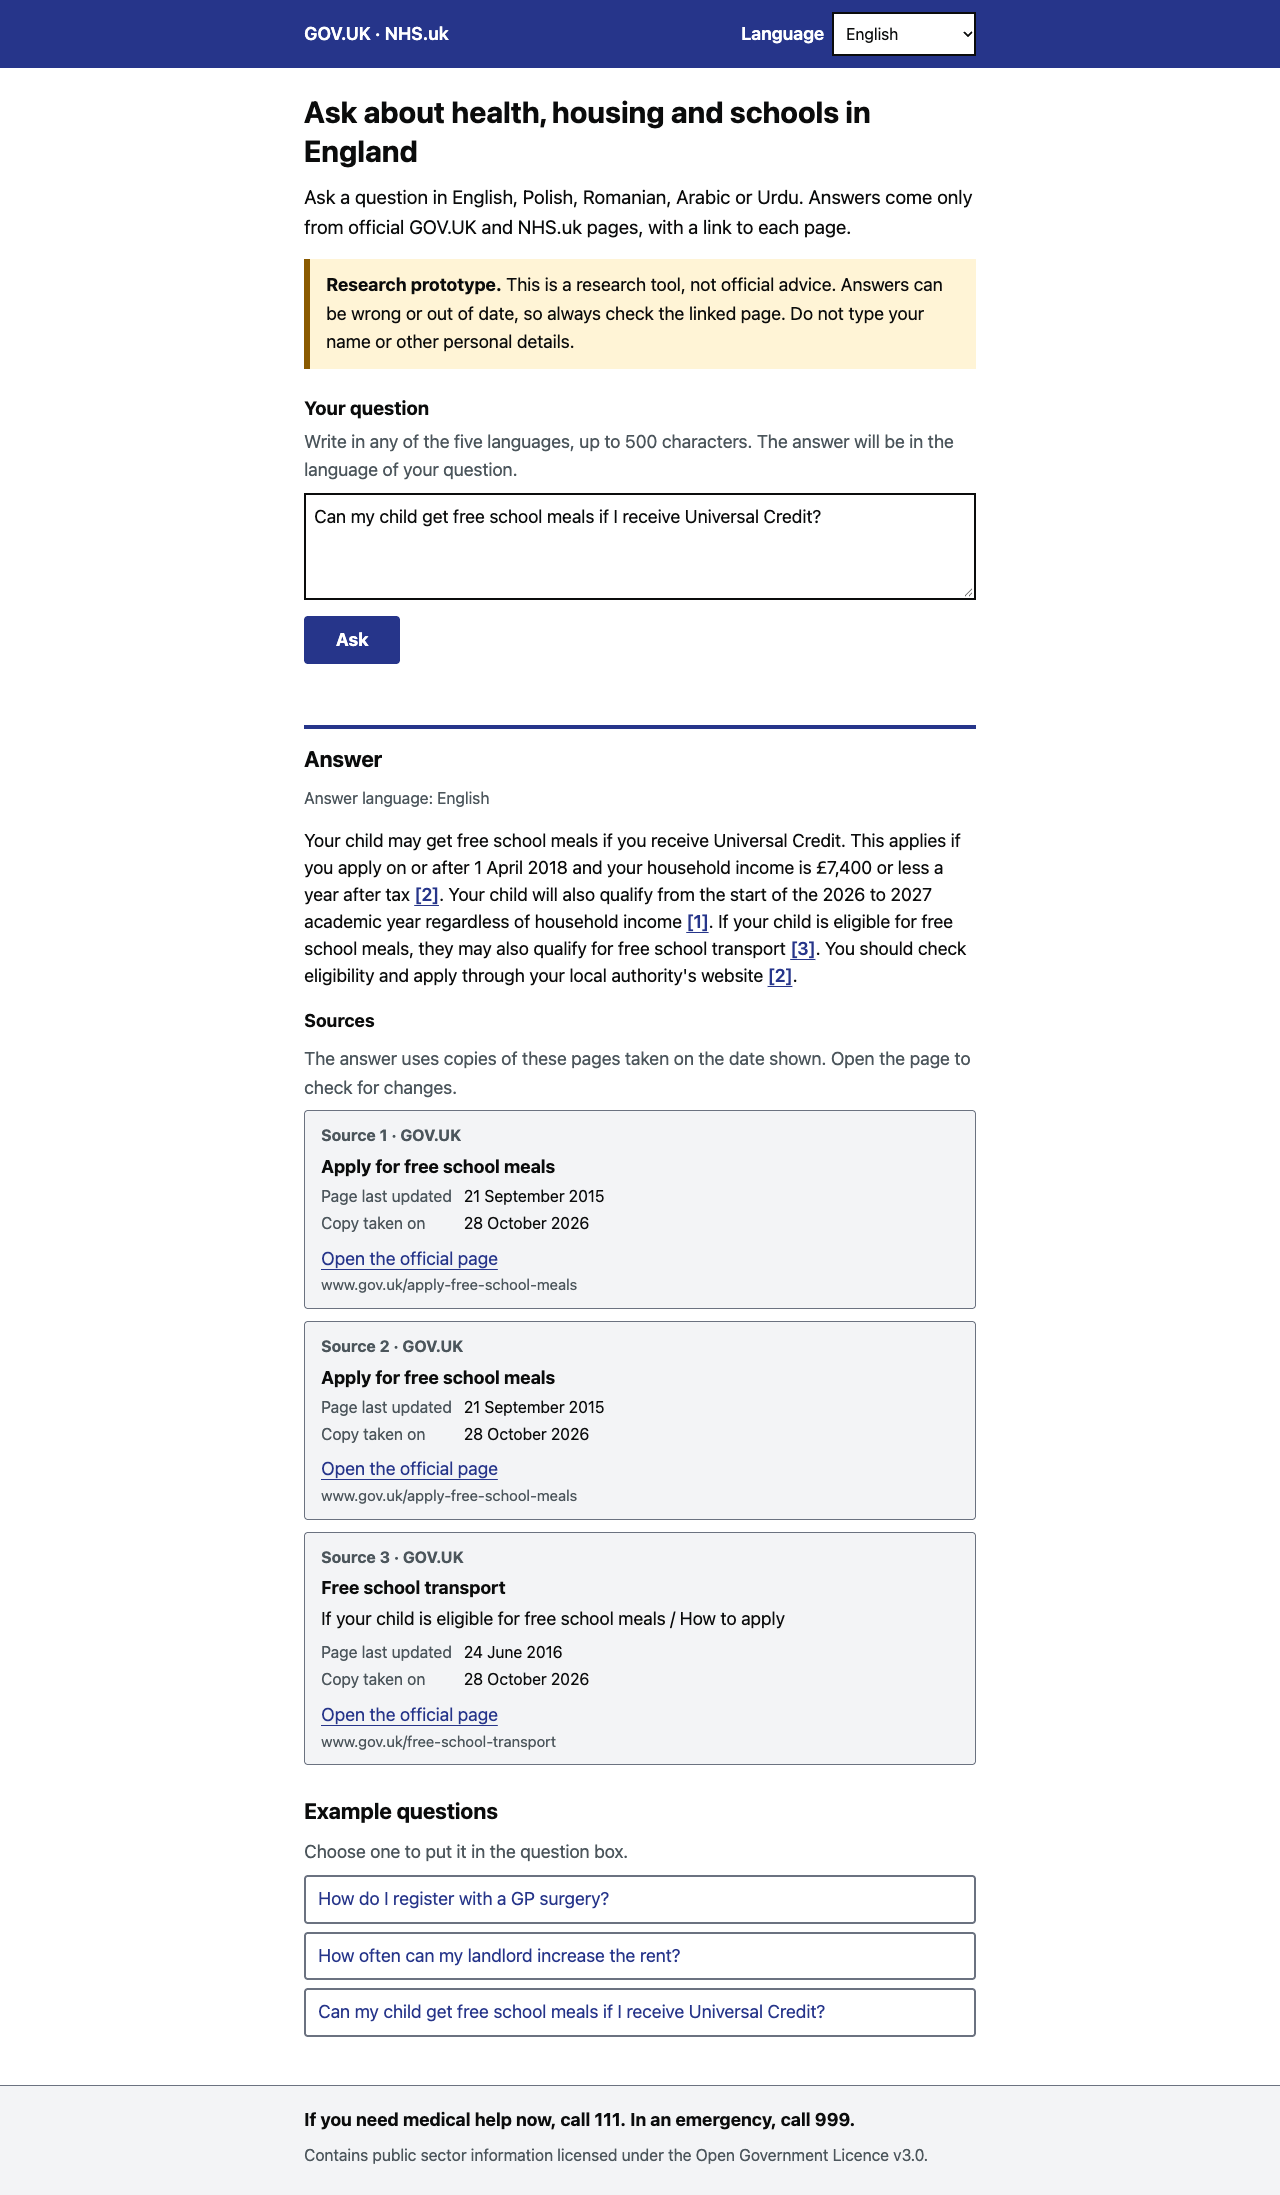

4-ar-answer-phone


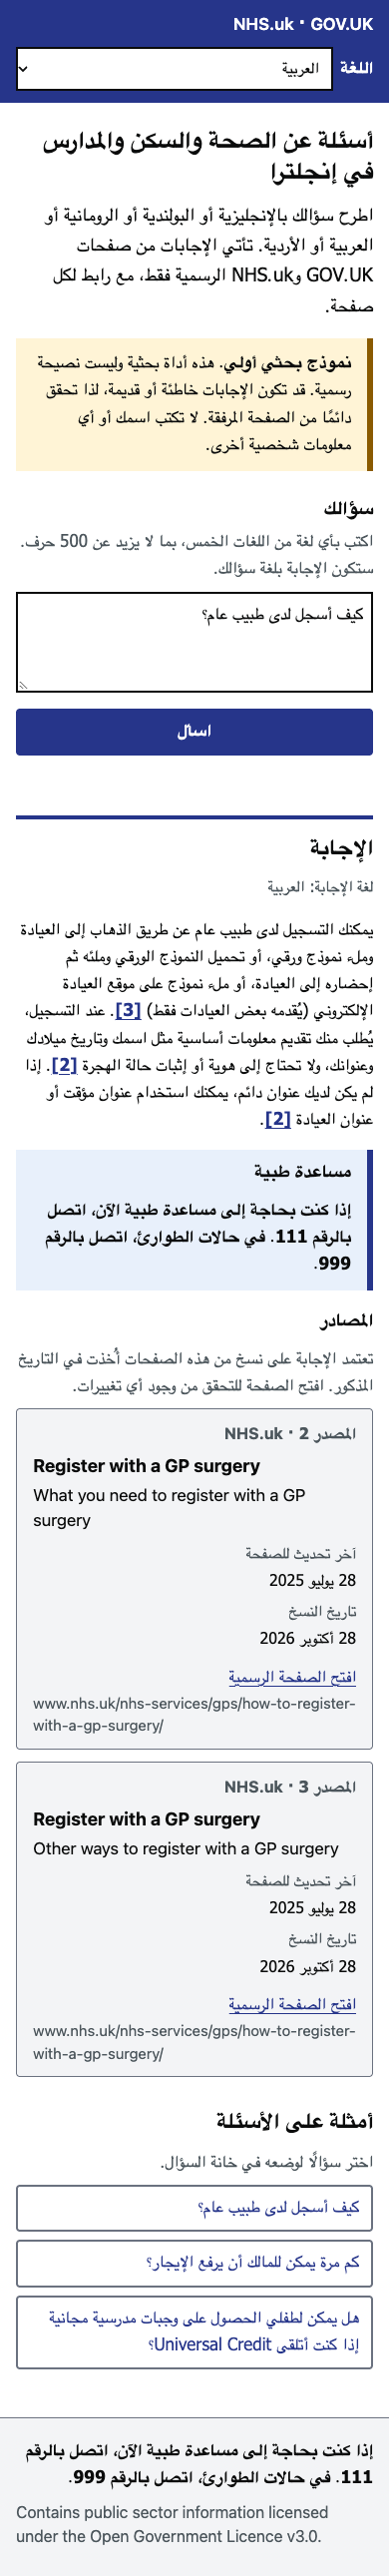

5-ur-answer-phone


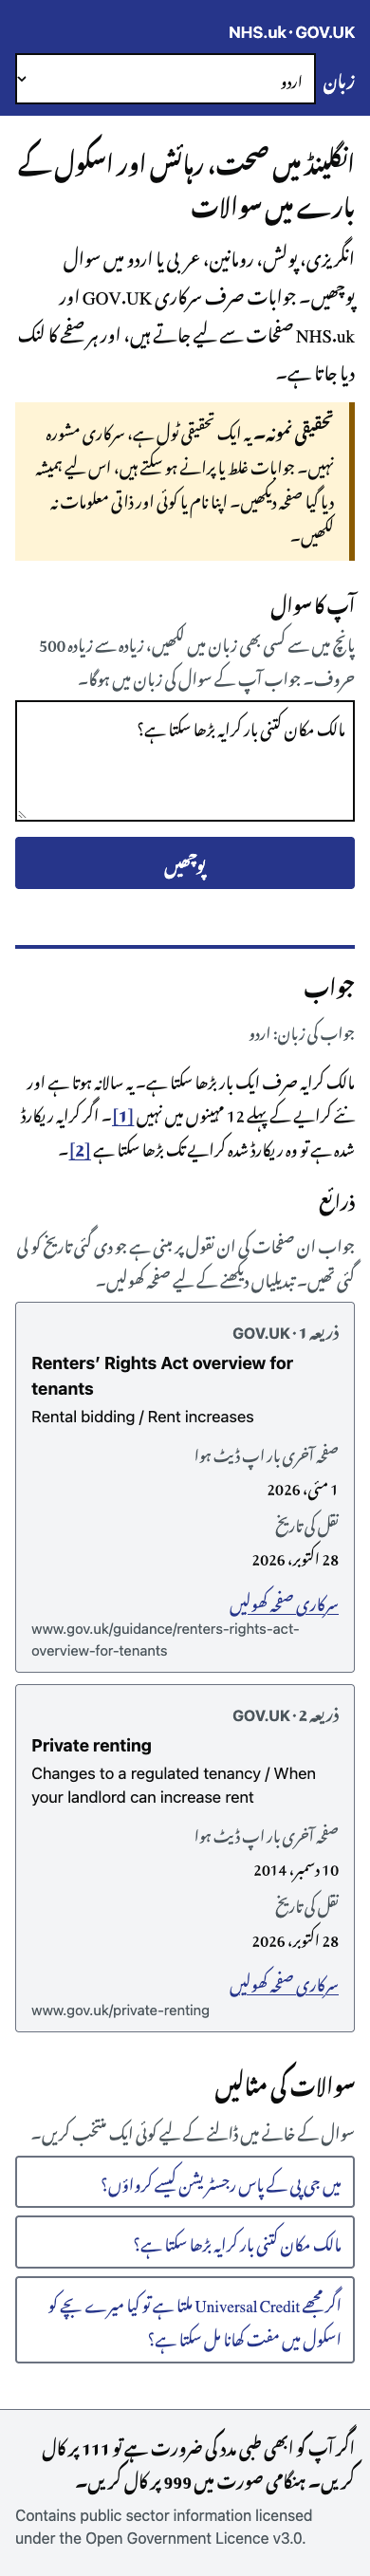

6-pl-refusal-phone


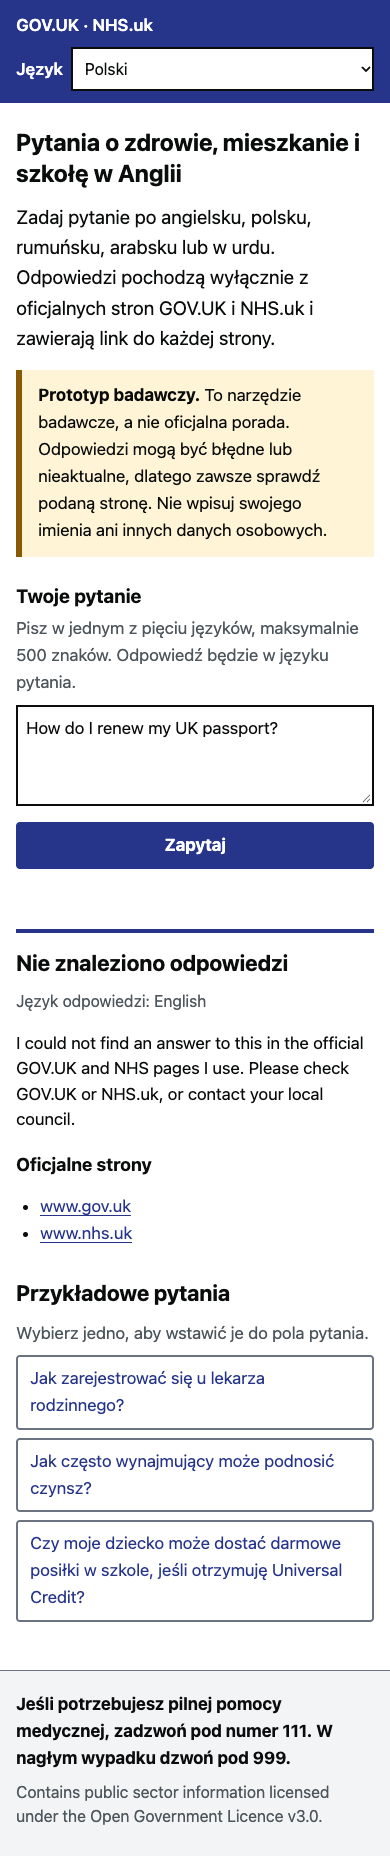

In [9]:
from IPython.display import Image, display
for name, width in [('3-en-cited-desktop', 640), ('4-ar-answer-phone', 300), ('5-ur-answer-phone', 300),
                    ('6-pl-refusal-phone', 300)]:
    print(name)
    display(Image(filename=str(ROOT / f'docs/week08-figures/{name}.png'), width=width))

## Findings

1. **The page works in all five languages.** The answer block takes the answer's own language and direction, so an Arabic question in the English interface gets a right-to-left Arabic answer; English titles and links inside Arabic and Urdu pages stay left-to-right.
2. **Accessibility (automated):** 0 axe violations in 10 states, lowest text contrast 6.54:1, no horizontal scroll at 320 px. Screen readers and real phones are still to check.
3. **Uncited answers** (about 4%: 6/150 in week 6, 10/248 in week 7) now still link to official pages.
4. **Live answers on the laptop were too slow this week.** Another virtual machine was using about 9 of the 15 CPU cores; NLLB on the CPU took over 3 minutes per sentence (0.3 s on the Apple GPU, now used by the web app) and Qwen did not produce 10 tokens in 150 s. Week 6 on the same laptop: about 19 s per answer. The Colab notebook times live answers on a T4 GPU (T35a); time the study machine again before week 9 sessions.

Full write-up: `docs/week-08-report.md`; accessibility details: `docs/accessibility.md`.